In [33]:
from golbal_variables import *

In [2]:
for item in MESSY_DATA_DIR.iterdir():
    type_label = "DIR" if item.is_dir() else "FILE"
    print(f"[{type_label}] {item.name}")

[DIR] ESC-50-master
[DIR] genres_stems
[DIR] mashups
[FILE] sample_submission.csv
[FILE] test.csv


In [15]:
for item in GRNRES_STEMS.iterdir():
    type_label = "DIR" if item.is_dir() else "FILE"
    print(f"[{type_label}] {item.name}")

[DIR] blues
[DIR] classical
[DIR] country
[DIR] disco
[DIR] hiphop
[DIR] jazz
[DIR] metal
[DIR] pop
[DIR] reggae
[DIR] rock


## Exploring EC50 data

In [4]:
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

In [6]:
esc50_df = pd.read_csv(ESC_50_MASTER/"meta/esc50.csv")

Files follow a specific pattern: {FOLD}-{CLIP_ID}-{TAKE}-{TARGET}.wav. The TARGET (0-49) is the class ID you are trying to predict.

In [7]:
esc50_df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [8]:
# Mapping of Target ID -> Class Name
id_to_class = {
    0: 'dog', 1: 'rooster', 2: 'pig', 3: 'cow', 4: 'frog', 5: 'cat', 6: 'hen', 7: 'insects', 8: 'sheep', 9: 'crow',
    10: 'rain', 11: 'sea_waves', 12: 'crackling_fire', 13: 'crickets', 14: 'chirping_birds', 15: 'water_drops', 16: 'wind', 17: 'pouring_water', 18: 'toilet_flush', 19: 'thunderstorm',
    20: 'crying_baby', 21: 'sneezing', 22: 'clapping', 23: 'breathing', 24: 'coughing', 25: 'footsteps', 26: 'laughing', 27: 'brushing_teeth', 28: 'snoring', 29: 'drinking_sipping',
    30: 'door_knock', 31: 'mouse_click', 32: 'keyboard_typing', 33: 'door_wood_creaks', 34: 'can_opening', 35: 'washing_machine', 36: 'vacuum_cleaner', 37: 'clock_alarm', 38: 'clock_tick', 39: 'glass_breaking',
    40: 'helicopter', 41: 'chainsaw', 42: 'siren', 43: 'car_horn', 44: 'engine', 45: 'train', 46: 'church_bells', 47: 'airplane', 48: 'fireworks', 49: 'hand_saw'
}

# Mapping of Target ID -> Major Category
def get_category(target_id):
    if 0 <= target_id <= 9: return "Animals"
    elif 10 <= target_id <= 19: return "Natural soundscapes & water sounds"
    elif 20 <= target_id <= 29: return "Human, non-speech sounds"
    elif 30 <= target_id <= 39: return "Interior/domestic sounds"
    elif 40 <= target_id <= 49: return "Exterior/urban noises"
    else: return "Unknown"

In [9]:
esc50_df["class_name"] = esc50_df["target"].map(id_to_class)
esc50_df["major_category"] = esc50_df["target"].apply(get_category)

In [17]:
esc50_df.head()

,filename,fold,target,category,esc10,src_file,take,class_name,major_category
0,1-100032-A-0.wav,1,0,dog,True,100032,A,dog,Animals
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A,chirping_birds,Natural soundscapes & water sounds
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A,vacuum_cleaner,Interior/domestic sounds
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B,vacuum_cleaner,Interior/domestic sounds
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A,thunderstorm,Natural soundscapes & water sounds


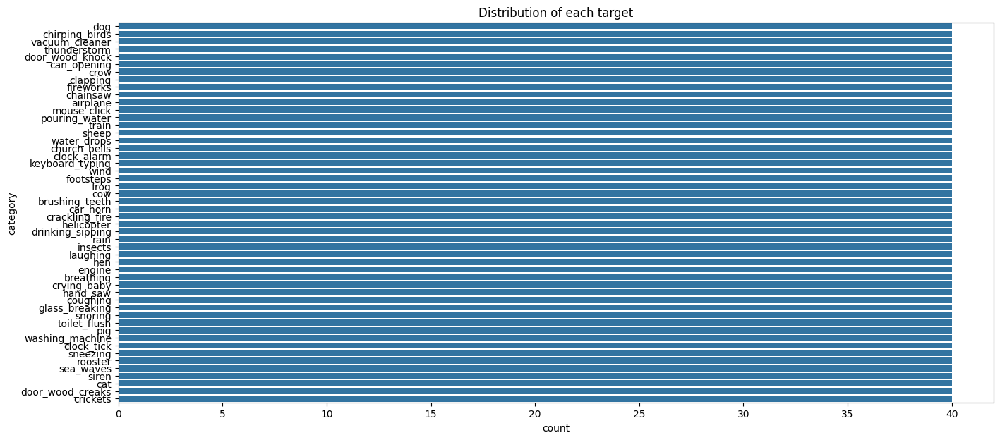

In [10]:
plt.figure(figsize=(16, 7))
sns.countplot(data=esc50_df, y="category")
plt.title("Distribution of each target")
plt.show()

C:\Users\visha\AppData\Local\Temp\ipykernel_14796\2655010572.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=esc50_df, y='major_category', palette='viridis')


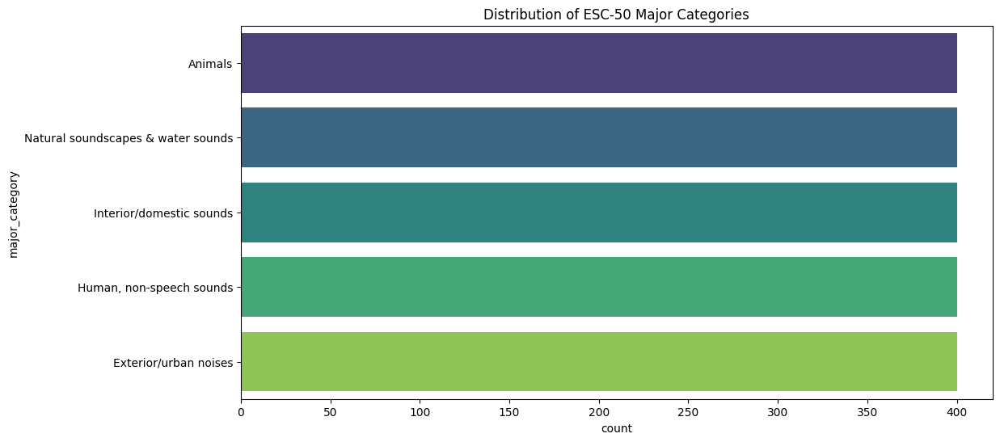

In [11]:
plt.figure(figsize=(12, 6))
sns.countplot(data=esc50_df, y='major_category', palette='viridis')
plt.title("Distribution of ESC-50 Major Categories")
plt.show()

All category have same distribution our data of ECS50 is balanced

## Checking wave forms

In [18]:
import librosa
import numba
import numpy
print(librosa.__version__)
print(numba.__version__)
print(numpy.__version__)

0.10.1
0.59.1
1.26.4


### Checking genres

In [27]:
from pathlib import Path
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from IPython.display import display

def plot_each_wav(folder: Path):
    files = list(folder.glob("*.wav")) 
    
    if not files:
        print(f"No .wav files found in {folder}")
        return

    fig, axes = plt.subplots(len(files), 1, figsize=(14, 3 * len(files)), squeeze=False)
    axes = axes.flatten()

    for ax, filename in zip(axes, files):
        data, sample_rate = librosa.load(filename, sr=None)
        librosa.display.waveshow(data, sr=sample_rate, ax=ax)
        
        ax.set_title(filename.name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")

    plt.tight_layout()
    plt.show()

    print("\nAudio Samples:\n")
    for filename in files:
        print(filename.name)
        display(ipd.Audio(str(filename)))
        print("-" * 60)

### BLUES

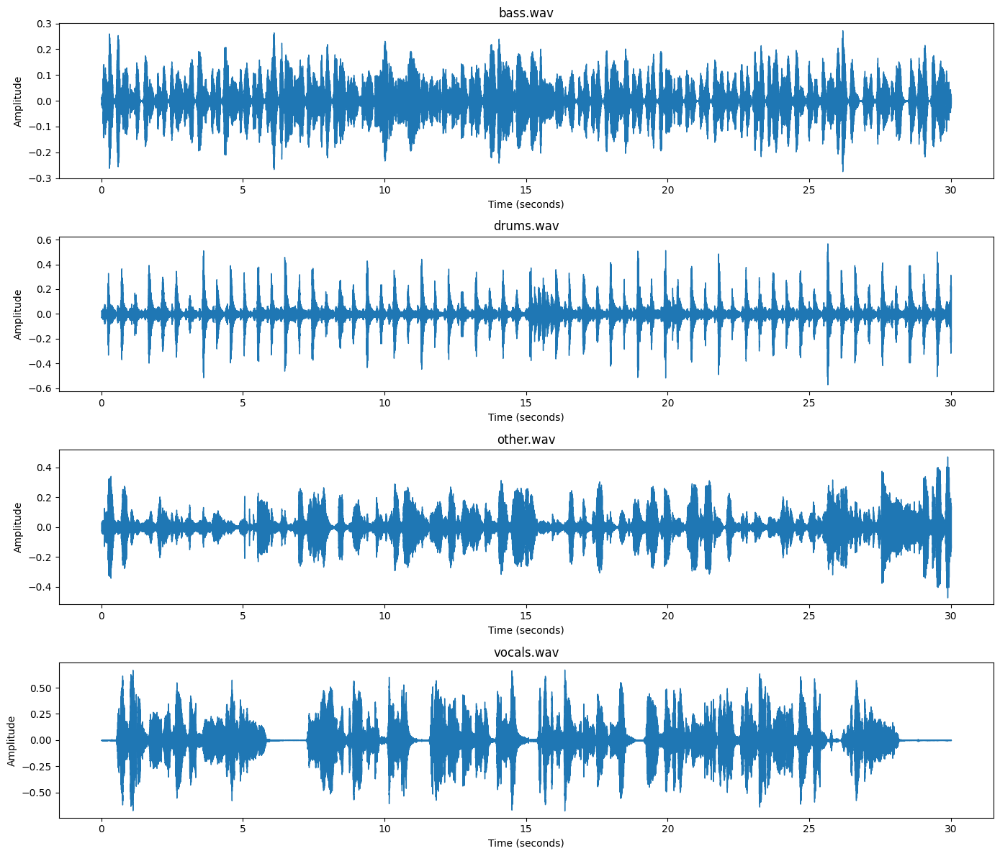


Audio Samples:

bass.wav


------------------------------------------------------------
drums.wav


------------------------------------------------------------
other.wav


------------------------------------------------------------
vocals.wav


------------------------------------------------------------


In [28]:
plot_each_wav(BLUES / "blues.00000")

### classical

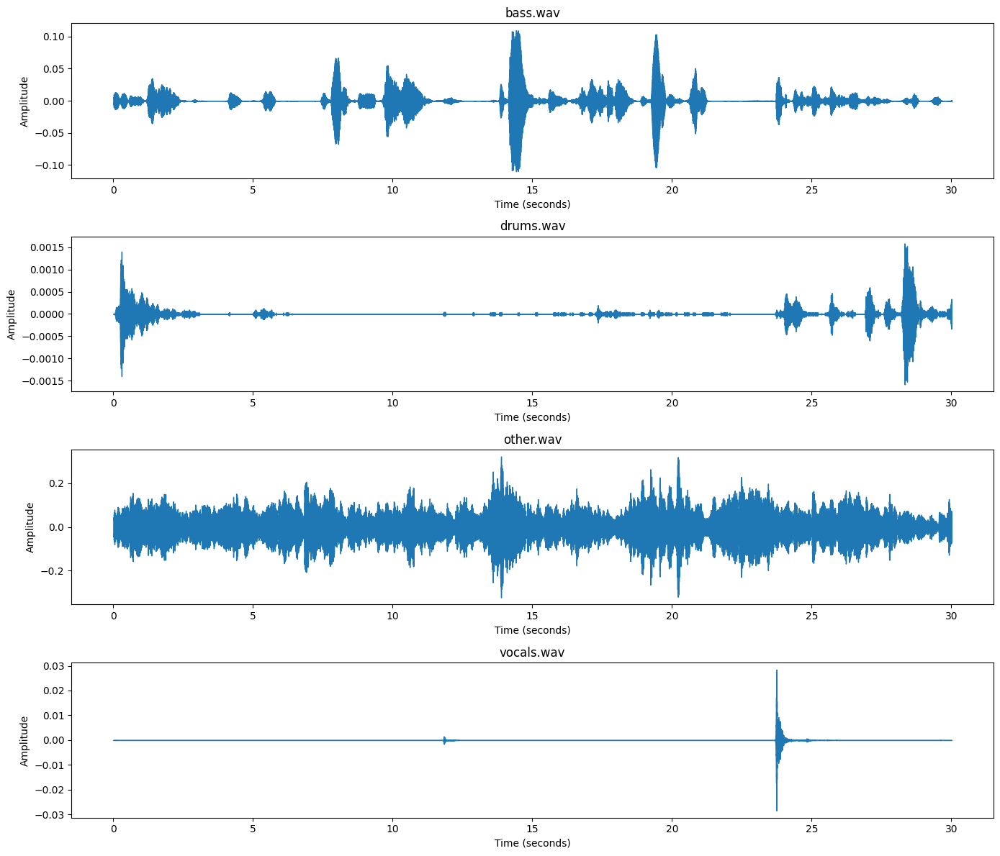


Audio Samples:

bass.wav


------------------------------------------------------------
drums.wav


------------------------------------------------------------
other.wav


------------------------------------------------------------
vocals.wav


------------------------------------------------------------


In [31]:
plot_each_wav(CLASSICAL / "classical.00000")

## 